# News Topic Classification for Short Headlines

**ARTI-404 · Group 5 · Option 3: News Topic Classification**

**Research question:** Which model performs better on *very short news headlines (six words or fewer)*?

- **Method 1:** TF-IDF + Logistic Regression
- **Method 2:** Pretrained all-MiniLM-L6-v2 embeddings + Logistic Regression
- **Output:** One of four topics — **World, Sports, Business, Sci/Tech**

> **How to run:** Open this notebook using **Jupyter Notebook** in the extracted project folder, then select **Kernel → Restart Kernel and Run All Cells**. Install packages once using `python -m pip install -r requirements.txt`. All prepared data, saved model parameters, and frozen test predictions are included in the project ZIP. The default **Try It** example works **offline** and requires no retraining.
>
> **Important:** This notebook loads the *approved frozen models and predictions*. It does **not** retrain on the test set. The optional live MiniLM demonstration downloads pretrained embeddings on first use and therefore needs Internet access once.

## 1. Setup & Imports

The notebook runs on **Python 3.11+** with paths relative to its folder. It prints package versions and checks all required files before starting; no local `.py` modules are imported.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import sys
from importlib.metadata import version

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

ROOT = Path.cwd()
LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
CLASS_IDS = [1, 2, 3, 4]
REQUIRED_FILES = [
    "data/train.csv", "data/val.csv", "data/test.csv", "data/split_manifest.json",
    "outputs/tfidf/tfidf_logreg.joblib", "outputs/tfidf/model_info.json",
    "models/embedder_name.txt", "models/minilm_logreg_coefficients.npz",
    "results/tfidf_predictions.csv", "results/minilm_predictions.csv",
]
missing = [name for name in REQUIRED_FILES if not (ROOT / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing project files: " + ", ".join(missing) +
        ". Extract the COMPLETE project ZIP and open the notebook from its folder."
    )

print("Project folder:", ROOT)
print("Python:", sys.version.split()[0])
for pkg in ("numpy", "pandas", "scikit-learn", "joblib", "matplotlib"):
    print(f"{pkg}: {version(pkg)}")
print("All required files found. Ready to run.")

Project folder: C:\Users\abdul\Downloads\NLP-Project-Final
Python: 3.11.14
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.8.0
joblib: 1.5.3
matplotlib: 3.11.2
All required files found. Ready to run.


## 2. Data Loading & Preprocessing

**Source:** [AG News](https://huggingface.co/datasets/sh0416/ag_news) — headline-only English text, with four categories.

The approved split was prepared **before modeling**. The original preprocessing normalizes whitespace, removes duplicate or conflicting titles, prevents overlapping headlines between splits, and creates a **stratified 10% validation holdout** from the training portion. Each headline has `word_count` and `is_short` (at most six words). The test set is **never** used to tune model settings.

The already prepared CSVs are included: no download or preprocessing rerun is necessary for **Run All**. The following cell verifies their integrity and split isolation.

In [2]:
train = pd.read_csv(ROOT / "data/train.csv")
val = pd.read_csv(ROOT / "data/val.csv")
test = pd.read_csv(ROOT / "data/test.csv")
splits = {"train": train, "val": val, "test": test}

manifest = json.loads((ROOT / "data/split_manifest.json").read_text(encoding="utf-8"))
for name, frame in splits.items():
    filename = f"{name}.csv"
    file_path = ROOT / "data" / filename
    original_bytes = file_path.read_bytes()
    assert len(original_bytes) == manifest[filename]["bytes"], f"Size mismatch: {filename}"
    assert hashlib.sha256(original_bytes).hexdigest() == manifest[filename]["sha256"], f"Checksum mismatch: {filename}"
    assert {"text", "label", "word_count", "is_short"}.issubset(frame.columns)
    assert not frame[["text", "label", "word_count", "is_short"]].isna().any().any()
    assert frame["label"].isin(CLASS_IDS).all()
    assert frame["word_count"].eq(frame["text"].str.split().str.len()).all()
    assert frame["is_short"].eq(frame["word_count"].le(6)).all()

def headline_keys(frame):
    return set(frame["text"].str.replace(r"\s+", " ", regex=True).str.strip().str.casefold())

keys = {name: headline_keys(frame) for name, frame in splits.items()}
assert keys["train"].isdisjoint(keys["val"])
assert keys["train"].isdisjoint(keys["test"])
assert keys["val"].isdisjoint(keys["test"])

split_table = pd.DataFrame([
    {"Split": name.title(), "Headlines": len(frame), "Very short (<=6 words)": int(frame["is_short"].sum())}
    for name, frame in splits.items()
])
display(split_table)
print("Checksums verified; no headline overlap between train, validation and test.")
display(test[["text", "label", "word_count", "is_short"]].head(3))

,Split,Headlines,Very short (<=6 words)
0,Train,101043,47011
1,Val,11227,5198
2,Test,7464,3554


Checksums verified; no headline overlap between train, validation and test.


,text,label,word_count,is_short
0,Fears for T N pension after talks,3,7,False
1,The Race is On: Second Private Team Sets Launc...,4,14,False
2,Ky. Company Wins Grant to Study Peptides (AP),4,8,False


## 3. TF-IDF + Logistic Regression

**Traditional baseline.** The pipeline converts headline words into sparse TF-IDF features, then applies **one-vs-rest Logistic Regression**. Six hyperparameter candidates were compared using the **validation macro F1**. The selected model uses unigrams and `C=8.0`. It was trained on **train only**, then saved.

The cell below loads the trusted saved pipeline and shows its settings. The `make_tfidf_pipeline()` function documents how this pipeline is constructed; **loading** the trained model, rather than fitting it again, keeps the standard run fast and preserves the submitted test scores.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline

def make_tfidf_pipeline(ngram_range=(1, 1), C=8.0):
    """Original training architecture. Fitting is not required for Run All."""
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True, strip_accents="unicode", ngram_range=ngram_range,
            max_features=40_000, min_df=1, sublinear_tf=True,
        )),
        ("classifier", OneVsRestClassifier(LogisticRegression(
            C=C, solver="liblinear", max_iter=300, tol=1e-3, random_state=42,
        ))),
    ])

def train_and_select_tfidf(training, validation):
    """Optional research reproduction: train on train, choose by validation F1.

    Not called by Run All; training would generate new model parameters.
    """
    best_score = -1.0
    best_model, best_settings = None, None
    for ngrams in ((1, 1), (1, 2)):
        for c_value in (0.5, 2.0, 8.0):
            candidate = make_tfidf_pipeline(ngram_range=ngrams, C=c_value)
            candidate.fit(training["text"], training["label"])
            predicted = candidate.predict(validation["text"])
            score = f1_score(validation["label"], predicted, labels=CLASS_IDS, average="macro")
            if score > best_score:
                best_score = score
                best_model = candidate
                best_settings = {"ngram_range": ngrams, "C": c_value, "val_macro_f1": score}
    return best_model, best_settings

# Saved by the team; only load serialized models from a trusted source.
tfidf_model = joblib.load(ROOT / "outputs/tfidf/tfidf_logreg.joblib")
tfidf_info = json.loads((ROOT / "outputs/tfidf/model_info.json").read_text(encoding="utf-8"))
print("Model:", tfidf_info["model"])
print("Selected validation settings:", tfidf_info["selected_settings"])
print("Validation macro F1:", round(tfidf_info["validation_metrics"]["overall"]["macro_f1"], 4))
assert list(tfidf_model.classes_) == CLASS_IDS
print("Frozen TF-IDF model loaded; no training performed.")

Model: TF-IDF + Logistic Regression
Selected validation settings: {'ngram_range': [1, 1], 'C': 8.0}
Validation macro F1: 0.8777
Frozen TF-IDF model loaded; no training performed.


## 4. MiniLM + Logistic Regression

**Pretrained embedding method.** The model maps lightly cleaned headlines to **384-dimensional, normalized sentence embeddings** using [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2). A separately fitted **multinomial Logistic Regression** classifier is trained on the training embeddings, with `C` selected on the validation embeddings; the selected value was **0.5**.

For reproducibility, the frozen classifier is stored as portable NumPy weights (`coef`, `intercept`, `classes`). The team's frozen **MiniLM test predictions** are already included; therefore **Run All does not download embeddings**. When **Try It** is set to `minilm`, the original pretrained MiniLM encoder is loaded on demand and may download once.

In [4]:
EMBEDDER_ID = (ROOT / "models/embedder_name.txt").read_text(encoding="utf-8").strip()
with np.load(ROOT / "models/minilm_logreg_coefficients.npz") as saved_weights:
    MINILM_COEF = saved_weights["coef"].copy()
    MINILM_INTERCEPT = saved_weights["intercept"].copy()
    MINILM_CLASSES = saved_weights["classes"].copy()
assert MINILM_COEF.shape == (4, 384)
assert MINILM_INTERCEPT.shape == (4,)
assert list(MINILM_CLASSES) == [0, 1, 2, 3]  # Original MiniLM labels are 0..3.

_HTML_TAG = re.compile(r"<[^>]+>")
_WHITESPACE = re.compile(r"\s+")

def light_clean(text):
    """Match the preprocessing used by the original MiniLM team code."""
    if not isinstance(text, str):
        return ""
    text = _HTML_TAG.sub(" ", text)
    text = text.replace("&lt;", "<").replace("&gt;", ">").replace("&amp;", "&")
    return _WHITESPACE.sub(" ", text).strip()

def train_minilm_classifier(training, validation, encoder):
    """Optional research reproduction: encode train/val and select C on val.

    This can be CPU-intensive and is NOT called by Run All.
    Pretrained encoder weights must already be available or downloaded.
    """
    x_train = encoder.encode(training["text"].map(light_clean).tolist(),
        batch_size=64, convert_to_numpy=True, normalize_embeddings=True)
    x_val = encoder.encode(validation["text"].map(light_clean).tolist(),
        batch_size=64, convert_to_numpy=True, normalize_embeddings=True)
    y_train = training["label"].to_numpy() - 1
    y_val = validation["label"].to_numpy() - 1
    best_model, best_c, best_score = None, None, -1.0
    for c_value in (0.5, 1.0, 2.0, 4.0, 8.0):
        candidate = LogisticRegression(C=c_value, solver="lbfgs",
            max_iter=2000, random_state=42)
        candidate.fit(x_train, y_train)
        score = f1_score(y_val, candidate.predict(x_val), average="macro")
        if score > best_score:
            best_model, best_c, best_score = candidate, c_value, score
    return best_model, {"C": best_c, "val_macro_f1": best_score}

_MINILM_EMBEDDER = None

def predict_minilm(headline, embedder=None):
    """Live prediction using frozen weights; never fits/retrains the classifier."""
    global _MINILM_EMBEDDER
    cleaned = light_clean(headline)
    if not cleaned:
        return {"ok": False, "message": "Please enter a non-empty English news headline."}
    if embedder is None:
        if _MINILM_EMBEDDER is None:
            from sentence_transformers import SentenceTransformer
            _MINILM_EMBEDDER = SentenceTransformer(EMBEDDER_ID)
        embedder = _MINILM_EMBEDDER
    x = np.asarray(embedder.encode([cleaned], convert_to_numpy=True, normalize_embeddings=True))
    assert x.shape == (1, 384), "Unexpected MiniLM embedding dimensions"
    logits = x @ MINILM_COEF.T + MINILM_INTERCEPT
    label = int(MINILM_CLASSES[np.argmax(logits, axis=1)[0]]) + 1
    return {"ok": True, "model": "MiniLM + Logistic Regression", "label_id": label, "topic": LABELS[label]}

print("Encoder:", EMBEDDER_ID)
print("Frozen classifier coefficient matrix:", MINILM_COEF.shape)
print("Ready: MiniLM test predictions can be evaluated offline.")

Encoder: sentence-transformers/all-MiniLM-L6-v2
Frozen classifier coefficient matrix: (4, 384)
Ready: MiniLM test predictions can be evaluated offline.


## 5. Evaluation & Comparison

**Fair comparison:** Both methods use precisely the same **held-out test headlines in the same row order**. We load their saved predictions, verify text alignment and class IDs, then calculate **Accuracy** and **macro F1** on (a) the full test set and (b) the subset of headlines with at most six words.

These predictions were generated by the original fitted team models **before** this evaluation. The test data is never used for model selection. The evaluation below is implemented **inside this notebook** (no `evaluation.py` dependency).

,Model,Test subset,N,Accuracy,Macro F1
0,TF-IDF + Logistic Regression,All test headlines,7464,88.29%,88.23%
1,TF-IDF + Logistic Regression,Very short (<=6 words),3554,86.72%,86.56%
2,MiniLM + Logistic Regression,All test headlines,7464,83.82%,83.75%
3,MiniLM + Logistic Regression,Very short (<=6 words),3554,81.06%,80.95%



 TF-IDF + Logistic Regression


,Pred World,Pred Sports,Pred Business,Pred Sci/Tech
Actual World,1668,80,86,48
Actual Sports,42,1787,32,25
Actual Business,77,58,1553,156
Actual Sci/Tech,79,55,136,1582



 MiniLM + Logistic Regression


,Pred World,Pred Sports,Pred Business,Pred Sci/Tech
Actual World,1608,97,110,67
Actual Sports,71,1701,71,43
Actual Business,92,88,1429,235
Actual Sci/Tech,85,51,198,1518


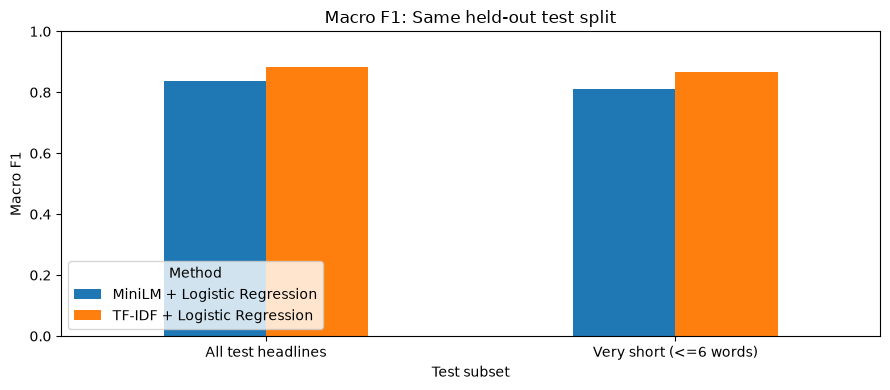

Validation passed: published held-out test scores reproduced.


In [5]:
def load_frozen_predictions(relative_path, reference):
    path = ROOT / relative_path
    frame = pd.read_csv(path)
    assert {"text", "prediction"}.issubset(frame.columns), f"Invalid format: {path.name}"
    assert len(frame) == len(reference), f"Different row count: {path.name}"
    assert frame["text"].equals(reference["text"]), f"Test row mismatch: {path.name}"
    preds = pd.to_numeric(frame["prediction"], errors="raise")
    assert preds.notna().all() and preds.isin(CLASS_IDS).all()
    assert preds.astype(int).eq(preds).all()
    return preds.astype(int).reset_index(drop=True)

predictions = {
    "TF-IDF + Logistic Regression": load_frozen_predictions("results/tfidf_predictions.csv", test),
    "MiniLM + Logistic Regression": load_frozen_predictions("results/minilm_predictions.csv", test),
}
subsets = {"All test headlines": np.ones(len(test), dtype=bool),
           "Very short (<=6 words)": test["is_short"].to_numpy(dtype=bool)}
metric_rows = []
for model_name, y_pred in predictions.items():
    for subset, mask in subsets.items():
        metric_rows.append({
            "Model": model_name, "Test subset": subset, "N": int(mask.sum()),
            "Accuracy": accuracy_score(test.loc[mask, "label"], y_pred[mask]),
            "Macro F1": f1_score(test.loc[mask, "label"], y_pred[mask],
                                labels=CLASS_IDS, average="macro", zero_division=0),
        })
metrics = pd.DataFrame(metric_rows)
display(metrics.style.format({"Accuracy": "{:.2%}", "Macro F1": "{:.2%}"}))

# Recalculate detailed metrics directly from the true labels and frozen predictions.
for name, y_pred in predictions.items():
    print("\n", name)
    cm = pd.DataFrame(confusion_matrix(test["label"], y_pred, labels=CLASS_IDS),
        index=["Actual " + LABELS[i] for i in CLASS_IDS],
        columns=["Pred " + LABELS[i] for i in CLASS_IDS])
    display(cm)

plot_data = metrics.pivot(index="Test subset", columns="Model", values="Macro F1")
ax = plot_data.loc[["All test headlines", "Very short (<=6 words)"]].plot.bar(
    figsize=(9, 4), rot=0, ylim=(0, 1), title="Macro F1: Same held-out test split")
ax.set_ylabel("Macro F1")
ax.legend(title="Method", loc="lower left")
plt.tight_layout()
plt.show()

# Optional reproducibility check against the team's published frozen summary.
assert len(test) == 7464 and int(test["is_short"].sum()) == 3554
assert abs(metrics.iloc[0]["Accuracy"] - 0.8829046087888531) < 1e-10
assert abs(metrics.iloc[2]["Accuracy"] - 0.8381564844587353) < 1e-10
print("Validation passed: published held-out test scores reproduced.")

**Interpretation.** On these frozen experiments, **TF-IDF + Logistic Regression** outperforms **MiniLM + Logistic Regression** on both the full test set and the very-short subset. Both models score lower on very-short headlines. These findings apply to the two trained classifiers in this project and do not imply that traditional methods always outperform pretrained approaches.

## 6. Error Analysis

We compare each model's prediction to the reference AG News category. The four possible patterns are: **both correct**, **only TF-IDF wrong**, **only MiniLM wrong**, and **both wrong**. The three cases shown below come from the *actual held-out test set*; no examples are invented or relabelled.

In [6]:
analysis = test.copy()
analysis["tfidf_prediction"] = predictions["TF-IDF + Logistic Regression"]
analysis["minilm_prediction"] = predictions["MiniLM + Logistic Regression"]
analysis["tfidf_correct"] = analysis["tfidf_prediction"].eq(analysis["label"])
analysis["minilm_correct"] = analysis["minilm_prediction"].eq(analysis["label"])
analysis["error_pattern"] = np.select(
    [~analysis["tfidf_correct"] & ~analysis["minilm_correct"],
     ~analysis["tfidf_correct"] & analysis["minilm_correct"],
     analysis["tfidf_correct"] & ~analysis["minilm_correct"]],
    ["both_wrong", "tfidf_only_wrong", "minilm_only_wrong"],
    default="both_correct",
)
for col in ("label", "tfidf_prediction", "minilm_prediction"):
    analysis[col + "_name"] = analysis[col].map(LABELS)
errors = analysis.loc[analysis["error_pattern"] != "both_correct"].copy()
print("Full test error categories:")
display(analysis["error_pattern"].value_counts().rename_axis("Pattern").reset_index(name="Cases"))

EXAMPLE_HEADLINES = [
    "Live: Olympics day four",
    "Google Lowers Its IPO Price Range",
    "Small computers can have multiple personalities, too",
]
examples = errors.loc[errors["text"].isin(EXAMPLE_HEADLINES)].copy()
assert len(examples) == 3
examples["_sort"] = examples["text"].map({h: i for i, h in enumerate(EXAMPLE_HEADLINES)})
examples = examples.sort_values("_sort")
display(examples[["text", "label_name", "tfidf_prediction_name",
                  "minilm_prediction_name", "error_pattern", "is_short"]].reset_index(drop=True))

Full test error categories:


,Pattern,Cases
0,both_correct,5966
1,minilm_only_wrong,624
2,both_wrong,584
3,tfidf_only_wrong,290


,text,label_name,tfidf_prediction_name,minilm_prediction_name,error_pattern,is_short
0,Live: Olympics day four,World,Sports,Sports,both_wrong,True
1,Google Lowers Its IPO Price Range,World,Business,Business,both_wrong,True
2,Small computers can have multiple personalitie...,Sci/Tech,Business,Sci/Tech,tfidf_only_wrong,False


**Explanation of the three examples:**

1. **“Live: Olympics day four”** — the reference label is **World**, but both models predict **Sports**. The Olympics sports keyword can dominate a very short headline even though the source category is World.
2. **“Google Lowers Its IPO Price Range”** — the reference label is **World**, but both predict **Business**. The words “IPO” and “Price” strongly indicate business; this also highlights potential ambiguity in reference labels.
3. **“Small computers can have multiple personalities, too”** — the reference category is **Sci/Tech**. TF-IDF predicts **Business**, while MiniLM predicts **Sci/Tech**. It illustrates how semantic context can help one model on a specific example, even when its aggregate test score is lower.

**Limitation:** A mismatch against the dataset label is not necessarily a clearly wrong human interpretation. The study uses English historical headlines, and the results may not transfer to other languages, topics, or current news.

## 7. Try It — Predict a New Headline

**Edit `NEW_HEADLINE`** below and run this cell. Use `CHOSEN_MODEL = "tfidf"` for the **offline demonstration**; set it to `"minilm"` to run the **pretrained embedding model** live (requires installing `sentence-transformers` and Internet access on its first download). Both choices reuse saved model parameters, with **no training**.

You can also test blank text: it should show a helpful instruction instead of crashing. The new headline is **not added** to the test set or final metrics.

In [7]:
def predict_tfidf(headline):
    if not isinstance(headline, str) or not headline.strip():
        return {"ok": False, "message": "Please enter a non-empty English news headline."}
    label = int(tfidf_model.predict([headline.strip()])[0])
    return {"ok": True, "model": "TF-IDF + Logistic Regression", "label_id": label, "topic": LABELS[label]}

def classify_headline(headline, model="tfidf"):
    model = model.strip().lower()
    if model == "tfidf":
        return predict_tfidf(headline)
    if model == "minilm":
        return predict_minilm(headline)
    return {"ok": False, "message": "Choose 'tfidf' or 'minilm'."}

NEW_HEADLINE = "Local football team wins regional championship"
CHOSEN_MODEL = "tfidf"  # Change to "minilm" for the optional live pretrained demo.

try:
    result = classify_headline(NEW_HEADLINE, model=CHOSEN_MODEL)
    if result["ok"]:
        print("Headline:", NEW_HEADLINE)
        print("Model:", result["model"])
        print("Predicted topic:", result["topic"])
    else:
        print(result["message"])
except (ImportError, OSError, RuntimeError) as exc:
    print("MiniLM live prediction needs the sentence-transformers package")
    print("and access to its pretrained weights (Internet on first use).")
    print("Details:", type(exc).__name__, str(exc)[:240])

assert classify_headline("   ")["ok"] is False  # Check empty-input handling.
print("Notebook complete. Frozen models were not retrained.")

Headline: Local football team wins regional championship
Model: TF-IDF + Logistic Regression
Predicted topic: Sports
Notebook complete. Frozen models were not retrained.


---
### Sources, reproducibility, and responsible use

- **Dataset:** [AG News](https://huggingface.co/datasets/sh0416/ag_news); original work: [Zhang, Zhao & LeCun (2015)](https://arxiv.org/abs/1509.01626).
- **Pretrained model:** [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2); [Sentence-BERT paper](https://aclanthology.org/D19-1410/).
- **Libraries:** [scikit-learn](https://scikit-learn.org/stable/), [Sentence Transformers](https://www.sbert.net/), pandas and NumPy.
- **Execution:** Jupyter Notebook, Python 3.11+, `python -m pip install -r requirements.txt`, then **Restart Kernel and Run All Cells**.
- **Reproduction:** Every scored prediction is verified against the original test headline text and labels; split file hashes are checked. Frozen models and prediction CSVs are supplied. MiniLM live inference is optional and may require an initial model download.
- **Academic practice:** Public data and pretrained weights are credited. AI assistance was used for coding/debugging/documentation; the team should review and explain each method and personally complete the report, appendix, and original example labels.